# Prioritised non-target screening (pNTA) as an early-warning proxy (RhineScan)

**Objective:** Look for unknown chemicals in Rhine water, remove what is just lab background, and rank the rest by how interesting they are (appear suddenly, increase downstream, have fragmentation data, match known pollutants).

In [1]:
# Setup, paths and (re)download if the session was wiped
import os, re, gc, json, pickle, hashlib, subprocess, zipfile, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests
warnings.filterwarnings("ignore")

WORK = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./work")
DATA_DIR = WORK / "wastewater_data" / "P1_pos"
OUT = WORK / "wastewater_watch_results"; OUT.mkdir(parents=True, exist_ok=True)
FEAT_DIR = OUT / "features"; FEAT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)

RECORD_ID, FILENAME = "17591915", "P1_pos.zip"

def ensure_data():
    if len(list(DATA_DIR.glob("*.mzXML"))) == 12:
        print("Data already present:", DATA_DIR); return
    zdir = WORK / "zip"; zdir.mkdir(exist_ok=True); dest = zdir / FILENAME
    rec = requests.get(f"https://zenodo.org/api/records/{RECORD_ID}", timeout=60).json()
    info = next(f for f in rec["files"] if f["key"] == FILENAME)
    algo, expected = info["checksum"].split(":", 1)
    if not dest.exists() or dest.stat().st_size != info["size"]:
        print("Downloading (~20 min on Kaggle)...")
        url = f"https://zenodo.org/records/{RECORD_ID}/files/{FILENAME}?download=1"
        subprocess.run(["curl", "-fL", "--retry", "5", "--retry-all-errors", "-C", "-", "-o", str(dest), url], check=True)
    h = hashlib.new(algo)
    with open(dest, "rb") as f:
        for chunk in iter(lambda: f.read(8 << 20), b""): h.update(chunk)
    assert h.hexdigest() == expected, "Checksum mismatch: do not use this file"
    with zipfile.ZipFile(dest) as z: z.extractall(WORK / "wastewater_data")
    dest.unlink()  # free disk
    print("Downloaded, verified, extracted.")

# Skip this call if every file already has cached features (see the extraction cell)
ensure_data()

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 1815M  100 1815M    0     0  2460k      0  0:12:35  0:12:35 --:--:-- 2720k


Downloaded, verified, extracted.


In [2]:
# Sample metadata (river order: 1 = most upstream)
files = sorted(DATA_DIR.glob("*.mzXML"))
LABELS = {"weil": "Weil", "karlsruhuhe": "Karlsruhe", "worms_li": "Worms", "koblenz": "Koblenz",
          "bad honnef": "Bad Honnef", "duesseldorf": "Duesseldorf", "duisburg": "Duisburg", "bimmen": "Bimmen"}
rows = []
for p in files:
    stem = p.stem.replace("_pos", "")
    if stem.startswith("MQ_"):
        rows.append(dict(path=p, name=stem, kind="blank", order=np.nan))
    else:
        num, raw = stem.split("_", 1)
        rows.append(dict(path=p, name=LABELS.get(raw, raw), kind="sample", order=int(num)))
meta = pd.DataFrame(rows)
meta = pd.concat([meta[meta.kind == "sample"].sort_values("order"), meta[meta.kind == "blank"].sort_values("name")], ignore_index=True)
SAMPLES = meta.loc[meta.kind == "sample", "name"].tolist()
BLANKS = meta.loc[meta.kind == "blank", "name"].tolist()
print("River order:", SAMPLES); print("Blanks:", BLANKS)

River order: ['Weil', 'Karlsruhe', 'Worms', 'Koblenz', 'Bad Honnef', 'Duesseldorf', 'Duisburg', 'Bimmen']
Blanks: ['MQ_1', 'MQ_2', 'MQ_3', 'MQ_4']


In [3]:
!pip install -q pyopenms

In [4]:
# Data-driven parameter check
import pyopenms as oms

def load_exp(path):
    e = oms.MSExperiment(); oms.MzXMLFile().load(str(path), e); return e

exp0 = load_exp(meta.path.iloc[0])
ms1_0 = [s for s in exp0.getSpectra() if s.getMSLevel() == 1]
pk = [s.get_peaks() for s in ms1_0[::40]]
inten = np.concatenate([p[1] for p in pk])
diffs = np.concatenate([np.diff(p[0]) for p in pk if len(p[0]) > 1])
print("Peaks per MS1 spectrum (median):", int(np.median([len(p[0]) for p in pk])))
print("Intensity quantiles 50/90/99/99.9%:", np.round(np.quantile(inten, [.5, .9, .99, .999]), 3))
print("Fraction of m/z spacings < 0.005 Da (profile-like if > 0.5):", round(float((diffs < 0.005).mean()), 3))
del exp0, ms1_0, pk; gc.collect()

# Intensities in this dataset are small; never rely on default absolute thresholds. Tune on the first file.
NOISE_QUANTILE = 0.90        # raise if a file yields > ~50k features, lower if < ~1k
NOISE_INT = float(np.quantile(inten, NOISE_QUANTILE))
MASS_ERR_PPM = 5.0
print("Noise threshold used:", NOISE_INT)

Peaks per MS1 spectrum (median): 1494
Intensity quantiles 50/90/99/99.9%: [ 0.175  0.649  2.759 20.819]
Fraction of m/z spacings < 0.005 Da (profile-like if > 0.5): 0.0
Noise threshold used: 0.6493407487869263


In [5]:
# Define feature extraction
# Feature extraction function (pyOpenMS 3.x API, verified on pyOpenMS 3.6)
def _as_list(x):
    return list(x) if x is not None else []

def extract(path, noise_int):
    exp = load_exp(path)
    ms1 = oms.MSExperiment(); ms2 = []
    for s in exp.getSpectra():
        lvl = s.getMSLevel()
        if lvl == 1:
            ms1.addSpectrum(s)
        elif lvl == 2 and len(s.getPrecursors()) > 0:
            mz, it = s.get_peaks()
            if len(mz) == 0: continue
            top = np.argsort(it)[::-1][:60]
            ms2.append(dict(rt=s.getRT(), pmz=s.getPrecursors()[0].getMZ(),
                            mz=mz[top].astype("float32"), it=it[top].astype("float32")))
    del exp
    ms1.sortSpectra(True)
    if float((diffs < 0.005).mean()) > 0.5:          # profile data: centroid first
        picker = oms.PeakPickerHiRes()
        try:
            out = oms.MSExperiment(); picker.pickExperiment(ms1, out, True); ms1 = out
        except TypeError:
            ms1 = picker.pickExperiment(ms1)
    mtd = oms.MassTraceDetection(); p = mtd.getDefaults()
    p.setValue("mass_error_ppm", float(MASS_ERR_PPM)); p.setValue("noise_threshold_int", float(noise_int))
    p.setValue("min_trace_length", 4.0); mtd.setParameters(p)
    try:
        traces = _as_list(mtd.run(ms1, 0))
    except TypeError:
        traces = []; mtd.run(ms1, traces, 0)
    epd = oms.ElutionPeakDetection(); pe = epd.getDefaults()
    pe.setValue("width_filtering", "fixed"); epd.setParameters(pe)
    try:
        split = _as_list(epd.detectPeaks(traces))
    except TypeError:
        split = []; epd.detectPeaks(traces, split)
    ffm = oms.FeatureFindingMetabo(); pf = ffm.getDefaults()
    pf.setValue("remove_single_traces", "true"); pf.setValue("report_convex_hulls", "false")
    pf.setValue("isotope_filtering_model", "none"); ffm.setParameters(pf)
    fm = oms.FeatureMap()
    try:
        ffm.run(split, fm)
    except TypeError:
        ffm.run(split, fm, [])
    feats = pd.DataFrame([dict(mz=f.getMZ(), rt=f.getRT(), intensity=f.getIntensity(),
                               quality=f.getOverallQuality(), charge=f.getCharge()) for f in fm])
    print(f"   traces={len(traces)}  split={len(split)}  features={len(feats)}")
    return feats, ms2


In [6]:
# Noise-level tuning
# Noise-level tuning: how many features does each threshold give on the first file?
for q in [0.50, 0.70, 0.80, 0.90]:
    thr = float(np.quantile(inten, q))
    f_, _ = extract(meta.path.iloc[0], thr)
    print(f">>> quantile {q:.2f}  threshold {thr:.3f}  ->  {len(f_)} features")

# CHOOSE: edit this number after reading the printout (aim for roughly 2,000-8,000 features per river sample)
NOISE_QUANTILE = 0.70
NOISE_INT = float(np.quantile(inten, NOISE_QUANTILE))
print("Using noise threshold:", NOISE_INT)

Progress of 'mass trace detection':
-- done [took 4.42 s (CPU), 4.38 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 4.41 s (CPU), 1.45 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 3.77 s (CPU), 1.12 s (Wall)] -- 
   traces=23095  split=17040  features=1528
>>> quantile 0.50  threshold 0.175  ->  1528 features
Progress of 'mass trace detection':
-- done [took 1.75 s (CPU), 1.72 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 2.39 s (CPU), 0.73 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 1.57 s (CPU), 0.44 s (Wall)] -- 
   traces=11417  split=8878  features=912
>>> quantile 0.70  threshold 0.298  ->  912 features
Progress of 'mass trace detection':
-- done [took 0.87 s (CPU), 0.86 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 1.40 s (CPU), 0.40 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 0.73 s (CPU), 0.22 s (Wall)] -- 
   traces=68

In [7]:
# Run feature extraction
# Run feature extraction on all files (resumable; one cached file per sample)
for _, r in meta.iterrows():
    fcsv = FEAT_DIR / f"{r['name']}.csv.gz"
    if fcsv.exists():
        print("cached:", r["name"]); continue
    t0 = time.time()
    feats, ms2 = extract(r["path"], NOISE_INT)
    feats.to_csv(fcsv, index=False)
    with open(FEAT_DIR / f"{r['name']}_ms2.pkl", "wb") as f: pickle.dump(ms2, f)
    print(f"{r['name']:<14} features={len(feats):>6}  MS2={len(ms2):>5}  {time.time()-t0:.0f}s")
    gc.collect()

Progress of 'mass trace detection':
-- done [took 1.70 s (CPU), 1.68 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 2.28 s (CPU), 0.68 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 1.63 s (CPU), 0.51 s (Wall)] -- 
   traces=11417  split=8878  features=912
Weil           features=   912  MS2= 1864  5s
Progress of 'mass trace detection':
-- done [took 1.86 s (CPU), 1.83 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 2.52 s (CPU), 0.77 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 1.77 s (CPU), 0.51 s (Wall)] -- 
   traces=12189  split=9682  features=970
Karlsruhe      features=   970  MS2= 1950  5s
Progress of 'mass trace detection':
-- done [took 2.05 s (CPU), 2.02 s (Wall)] -- 
Progress of 'elution peak detection':
-- done [took 2.91 s (CPU), 0.89 s (Wall)] -- 
Progress of 'assembling mass traces to features':
-- done [took 2.75 s (CPU), 0.72 s (Wall)] -- 
   traces=15697  split=12859 

In [8]:
# Cross-sample feature grouping
from scipy.spatial import cKDTree
PPM_TOL, RT_TOL = 5.0, 15.0   # no RT alignment: same LC method, so a modest RT window is used

frames = []
for _, r in meta.iterrows():
    d = pd.read_csv(FEAT_DIR / f"{r['name']}.csv.gz"); d["sample"] = r["name"]; frames.append(d)
allf = pd.concat(frames, ignore_index=True)
print(allf.groupby("sample").size().reindex(SAMPLES + BLANKS).to_string())

def seeded_clusters(df, ppm, rt_tol):
    X = np.c_[np.log(df.mz.values) * 1e6 / ppm, df.rt.values / rt_tol]
    tree = cKDTree(X)
    inten_, samp = df.intensity.values, df["sample"].values
    cid = np.full(len(df), -1); k = 0
    for i in np.argsort(-inten_):
        if cid[i] >= 0: continue
        used = set()
        for j in sorted(tree.query_ball_point(X[i], r=1.0, p=np.inf), key=lambda j: -inten_[j]):
            if cid[j] >= 0 or samp[j] in used: continue
            cid[j] = k; used.add(samp[j])
        k += 1
    return cid

allf["cid"] = seeded_clusters(allf, PPM_TOL, RT_TOL)
M = (allf.pivot_table(index="cid", columns="sample", values="intensity", aggfunc="max")
         .reindex(columns=SAMPLES + BLANKS).fillna(0.0))
info = allf.groupby("cid").agg(mz=("mz", "median"), rt=("rt", "median")).loc[M.index]
print("Feature groups:", len(M))

sample
Weil            912
Karlsruhe       970
Worms          1389
Koblenz        1178
Bad Honnef     1235
Duesseldorf    1136
Duisburg       1491
Bimmen         1311
MQ_1           4013
MQ_2           1049
MQ_3            606
MQ_4            635
Feature groups: 9053


In [9]:
# Requantification from raw data
# Re-measure every feature in every file from the raw data (gap filling)
# Why: the peak finder misses weak peaks, so a 0 in the table often means "not found", not "not there".
EIC_PPM = 5.0                 # m/z window for the extracted-ion chromatogram (EIC)
EIC_RT = 15.0                 # seconds either side of the feature's RT where the apex is searched
APEX_MIN = 5 * NOISE_INT      # minimum apex intensity to call a signal "detected" (= detection limit, LOD)
PEAK_RATIO = 3.0              # apex must be at least 3x the median level of the surrounding 2 minutes

def load_ms1_flat(path):
    """All MS1 peaks of one file as flat arrays sorted by m/z (fast lookup of any m/z window)."""
    e = load_exp(path)
    rts, mzl, itl, sidl = [], [], [], []
    n = 0
    for s in e.getSpectra():
        if s.getMSLevel() != 1: continue
        mz, it = s.get_peaks()
        rts.append(s.getRT()); mzl.append(mz); itl.append(it)
        sidl.append(np.full(len(mz), n, dtype=np.int32)); n += 1
    mz = np.concatenate(mzl); it = np.concatenate(itl).astype(np.float32); sid = np.concatenate(sidl)
    o = np.argsort(mz, kind="stable")
    return np.asarray(rts), mz[o], it[o], sid[o]

def eic_apex(scan_rt, mz_s, it_s, sid_s, mz0, rt0):
    tol = mz0 * EIC_PPM * 1e-6
    lo, hi = np.searchsorted(mz_s, [mz0 - tol, mz0 + tol])
    if hi <= lo: return 0.0
    s, v = sid_s[lo:hi], it_s[lo:hi]
    a, b = np.searchsorted(scan_rt, [rt0 - 60.0, rt0 + 60.0])
    m = (s >= a) & (s < b)
    if m.sum() < 3: return 0.0
    eic = np.bincount(s[m] - a, weights=v[m], minlength=b - a)       # intensity per scan
    rts = scan_rt[a:b]
    sm = np.convolve(eic, np.ones(3) / 3, mode="same")               # light smoothing
    inwin = np.abs(rts - rt0) <= EIC_RT
    if not inwin.any(): return 0.0
    k = int(np.argmax(np.where(inwin, sm, -1.0))); apex = float(sm[k])
    bg = float(np.median(eic))
    n_pos = int((eic[np.abs(rts - rts[k]) <= 5.0] > 0).sum())        # peak must span >= 3 scans
    ok = (apex >= APEX_MIN) and (apex >= PEAK_RATIO * bg) and (n_pos >= 3)
    return apex if ok else 0.0

RQ_FILE = OUT / "requantified_matrix.csv.gz"
cand = M.index[(M > 0).sum(axis=1) >= 2]          # feature groups seen in at least 2 files
if RQ_FILE.exists():
    Mq = pd.read_csv(RQ_FILE, index_col=0); Mq.index = Mq.index.astype(M.index.dtype)
    print("Loaded cached requantified matrix")
else:
    Mq = pd.DataFrame(0.0, index=cand, columns=M.columns)
    mz_c, rt_c = info.loc[cand, "mz"].values, info.loc[cand, "rt"].values
    for _, r in meta.iterrows():
        t0 = time.time()
        scan_rt, mz_s, it_s, sid_s = load_ms1_flat(r["path"])
        Mq[r["name"]] = [eic_apex(scan_rt, mz_s, it_s, sid_s, m0, r0) for m0, r0 in zip(mz_c, rt_c)]
        del scan_rt, mz_s, it_s, sid_s; gc.collect()
        print(f"{r['name']:<12} detected {(Mq[r['name']] > 0).sum():>5} / {len(cand)}  ({time.time()-t0:.0f}s)")
    Mq.to_csv(RQ_FILE)

M_ffm = M                                   # keep the original peak-finder matrix for reference
M = Mq[SAMPLES + BLANKS]
info = info.loc[M.index]
print("Feature groups after requantification:", len(M))

Weil         detected  1071 / 2028  (3s)
Karlsruhe    detected  1122 / 2028  (4s)
Worms        detected  1294 / 2028  (5s)
Koblenz      detected  1265 / 2028  (4s)
Bad Honnef   detected  1256 / 2028  (4s)
Duesseldorf  detected  1254 / 2028  (5s)
Duisburg     detected  1310 / 2028  (5s)
Bimmen       detected  1299 / 2028  (6s)
MQ_1         detected  1124 / 2028  (6s)
MQ_2         detected   998 / 2028  (4s)
MQ_3         detected   762 / 2028  (3s)
MQ_4         detected   763 / 2028  (3s)
Feature groups after requantification: 2028


Kept after blank filter (all blanks, fold 10, >= 2 sites): 613 / 2028
Kept using only MQ_3/MQ_4 as blanks: 789


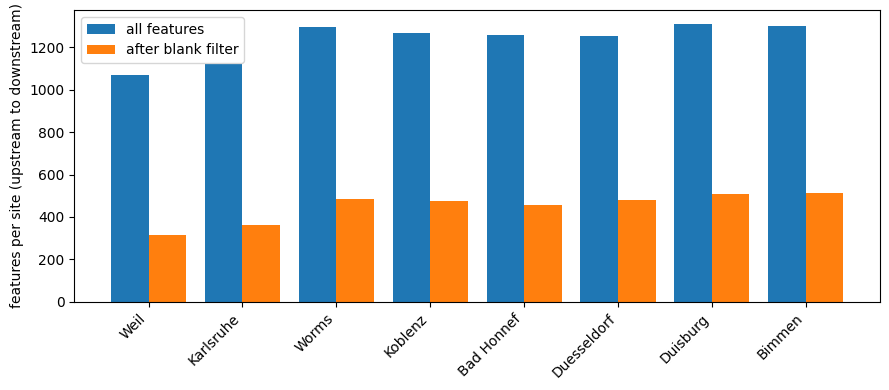

In [10]:
# Blank filter
BLANK_FOLD, MIN_SITES = 10, 2
def blank_filter(M, blanks, fold=BLANK_FOLD):
    b = M[blanks].max(axis=1)
    S = M[SAMPLES]
    Sc = S.where(S.gt(fold * b, axis=0), 0.0)
    return Sc, (Sc > 0).sum(axis=1)

Sc, n_sites = blank_filter(M, BLANKS)
keep = n_sites >= MIN_SITES
print(f"Kept after blank filter (all blanks, fold {BLANK_FOLD}, >= {MIN_SITES} sites): {int(keep.sum())} / {len(M)}")
# Sensitivity: MQ_1/MQ_2 have higher background in the Day 1 QC; compare with MQ_3/MQ_4 only
_, n2 = blank_filter(M, [b for b in BLANKS if b in ("MQ_3", "MQ_4")] or BLANKS)
print(f"Kept using only MQ_3/MQ_4 as blanks: {int((n2 >= MIN_SITES).sum())}")

raw_n = (M[SAMPLES] > 0).sum(); filt_n = (Sc > 0).sum()
fig, ax = plt.subplots(figsize=(9, 4))
idx = np.arange(len(SAMPLES))
ax.bar(idx - 0.2, raw_n.values, 0.4, label="all features"); ax.bar(idx + 0.2, filt_n.values, 0.4, label="after blank filter")
ax.set_xticks(idx); ax.set_xticklabels(SAMPLES, rotation=45, ha="right"); ax.set_ylabel("features per site (upstream to downstream)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_features_blank_filter.png", dpi=160); plt.show()

Core features used for normalisation: 235
sample
Weil          -0.32
Karlsruhe     -0.31
Worms         -0.09
Koblenz        0.02
Bad Honnef     0.13
Duesseldorf    0.11
Duisburg       0.20
Bimmen         0.09


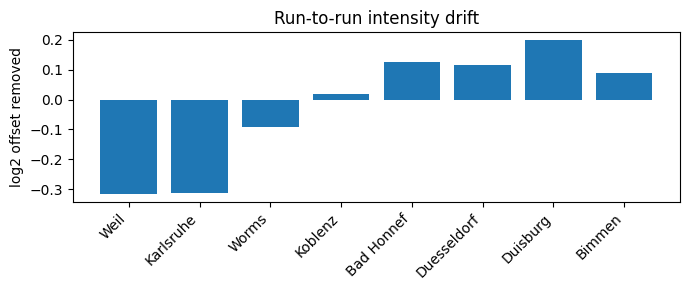

In [11]:
# Normalisation
# Normalise sites to remove run-to-run intensity drift
# Uses "core" features detected at ALL river sites: their typical site-to-site offset is treated as instrument drift.
core = (Sc > 0).all(axis=1)
print("Core features used for normalisation:", int(core.sum()))
if core.sum() >= 20:
    Lc = np.log2(Sc[core])
    offset = Lc.sub(Lc.mean(axis=1), axis=0).median(axis=0)       # per-site log2 offset (0 = typical)
    print(offset.round(2).to_string())
    Sc_raw = Sc.copy()
    Sc = Sc.mul(2.0 ** (-offset), axis=1)                           # later cells now use the normalised table
    fig, ax = plt.subplots(figsize=(7, 3)); ax.bar(range(len(SAMPLES)), offset.values)
    ax.set_xticks(range(len(SAMPLES))); ax.set_xticklabels(SAMPLES, rotation=45, ha="right")
    ax.set_ylabel("log2 offset removed"); ax.set_title("Run-to-run intensity drift")
    plt.tight_layout(); plt.savefig(FIG_DIR / "fig1b_normalisation_offsets.png", dpi=160); plt.show()
else:
    print("Too few core features; no normalisation applied")

In [12]:
# Spatial dynamics
# Spatial dynamics: trend along the river and "emission-like" jumps
# Non-detects are set to the detection limit (LOD) instead of 0, so a jump means "real increase above what we can see".
LOD = APEX_MIN
F = info.loc[keep[keep].index].copy()
Sk = Sc.loc[F.index]
L = np.log2(np.maximum(Sk.values, LOD))
det = Sk.values > 0
n = L.shape[1]; x = np.arange(n)
R = pd.DataFrame(L).rank(axis=1).values
Rc = R - R.mean(1, keepdims=True); xc = x - x.mean()
den = np.sqrt((Rc ** 2).sum(1)) * np.sqrt((xc ** 2).sum())
rho = np.divide(Rc @ xc, den, out=np.zeros(len(den)), where=den > 0)       # + = increases downstream, - = decreases

jump = np.full(L.shape, np.nan)
for k in range(2, n):                                                       # site k vs median of all sites upstream of it
    jump[:, k] = L[:, k] - np.median(L[:, :k], axis=1)
kbest = np.nanargmax(jump, axis=1)
F["max_int"] = Sk.max(axis=1).values
F["n_sites"] = det.sum(axis=1)
F["rho"] = rho
F["jump_up"] = jump[np.arange(len(F)), kbest]                               # log2 fold increase vs upstream (signed)
F["jump_site"] = np.array(SAMPLES)[kbest]
F["persist"] = [det[i, k:].mean() for i, k in enumerate(kbest)]             # fraction of sites from the jump onward still detected
F["down_minus_up"] = L[:, -3:].mean(1) - L[:, :3].mean(1)
print(F[["max_int", "n_sites", "rho", "jump_up", "persist", "down_minus_up"]].describe().round(2).to_string())

       max_int  n_sites     rho  jump_up  persist  down_minus_up
count   613.00   613.00  613.00   613.00   613.00         613.00
mean     23.13     5.80    0.12     1.30     0.89           0.17
std     139.92     2.26    0.56     1.62     0.23           0.84
min       1.43     2.00   -1.00    -0.56     0.00          -2.29
25%       3.14     4.00   -0.29     0.25     1.00          -0.30
50%       5.54     6.00    0.29     0.65     1.00           0.12
75%      12.68     8.00    0.54     1.74     1.00           0.50
max    3054.43     8.00    0.98     9.54     1.00           4.70


In [13]:
# Adduct, isotope and solvent-front cleanup
# Merge duplicate signals (isotopes / adducts) and drop the solvent-front region
RT_MIN_S = 150.0                                                     # features before 2.5 min are unretained junk
DELTAS = {"13C": 1.003355, "NH4": 17.026549, "Na": 21.981944, "K": 37.955881}   # mass difference to the [M+H]+ ion

def collapse_adducts(F, S, ppm=4.0, rt_tol=6.0, min_corr=0.7):
    ids = F.index.values; mz = F.mz.values; rt = F.rt.values
    prof = np.log2(np.maximum(S.loc[ids].values, LOD))
    parent = {i: i for i in ids}
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    X = np.c_[np.log(mz) * 1e6 / ppm, rt / rt_tol]
    tree = cKDTree(X); links = 0
    for name, d in DELTAS.items():
        Xq = np.c_[np.log(mz + d) * 1e6 / ppm, rt / rt_tol]
        for a, nb in enumerate(tree.query_ball_point(Xq, r=1.0, p=np.inf)):
            for b in nb:
                if b == a: continue
                c = np.corrcoef(prof[a], prof[b])[0, 1]               # same compound -> same pattern along the river
                if np.isfinite(c) and c >= min_corr:
                    ra, rb = find(ids[a]), find(ids[b])
                    if ra != rb: parent[ra] = rb; links += 1
    return np.array([find(i) for i in ids]), links

grp, n_links = collapse_adducts(F, Sc)
F["group"] = grp
F["group_size"] = F.groupby("group")["mz"].transform("size")
F["is_rep"] = F.groupby("group")["mz"].transform("min") == F["mz"]       # keep the lowest m/z ([M+H]+) as representative
F_all = F.copy(); F_all.to_csv(OUT / "features_before_dedup.csv")
n0 = len(F)
F = F[F.is_rep & (F.rt >= RT_MIN_S)].copy()
print(f"Features: {n0} -> {len(F)}  (merged duplicates: {int((~F_all.is_rep).sum())}, "
      f"dropped RT < {RT_MIN_S/60:.1f} min: {int(((F_all.rt < RT_MIN_S) & F_all.is_rep).sum())})")

Features: 613 -> 547  (merged duplicates: 39, dropped RT < 2.5 min: 27)


         compound  mz_theo  ppm_raw  ppm_fit  residual
0   Benzotriazole   120.06    -8.80    -6.58     -2.22
1     Venlafaxine   278.21    -4.92    -4.82     -0.11
2      Metoprolol   268.19    -3.94    -4.93      0.99
3       Valsartan   436.23    -2.60    -3.05      0.46
4     Lamotrigine   256.02    -3.62    -5.07      1.44
5      Citalopram   325.17    -3.78    -4.29      0.51
6  Clarithromycin   748.48    -0.23     0.43     -0.66
7    Fexofenadine   502.30    -2.73    -2.32     -0.42
Mass-error model (linear): -7.92 ppm + 11.17 ppm per 1000 m/z; residual MAD 0.59 ppm


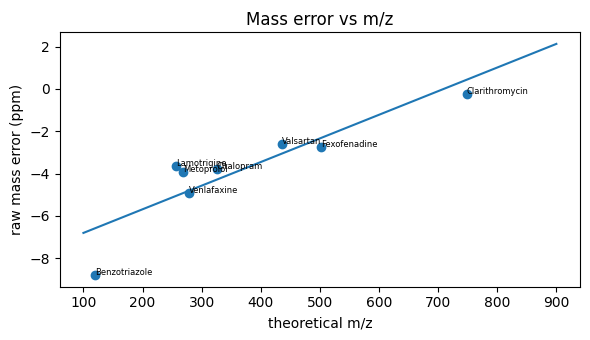

          compound     formula    mz_theo   cid     mz_obs   ppm  rt_min  n_sites    max_int   rho
0    Carbamazepine   C15H12N2O  237.10224  2520  237.10268  1.86    9.25        8  12.401340  0.88
1    Benzotriazole      C6H5N3  120.05562  4699  120.05536 -2.22    6.13        8   9.212101  0.38
2      Venlafaxine   C17H27NO2  278.21146  5412  278.21143 -0.11    7.16        8   5.470196  0.67
3         Tramadol   C16H25NO2  264.19581  4104  264.19596  0.59    5.91        8   7.934704  0.93
4         Tramadol   C16H25NO2  264.19581  5313  264.19600  0.72    6.36        8   5.133487  0.62
5       Metoprolol   C15H25NO3  268.19072  1677  268.19099  0.99    6.31        8  23.329402  0.83
6       Irbesartan   C25H28N6O  429.23974  2599  429.23876 -2.27    9.57        8  12.319280  0.93
7        Valsartan  C24H29N5O3  436.23432  4075  436.23452  0.46   11.60        8   5.538498  0.88
8      Lamotrigine   C9H7Cl2N5  256.01513  3886  256.01550  1.44    6.18        8   8.823576  0.79
9       Ci

In [14]:
# Suspect screening with an m/z-dependent mass-error correction ([M+H]+, MS1 only)
MASS = dict(C=12.0, H=1.00782503207, N=14.0030740048, O=15.99491461956, S=31.97207100,
            Cl=34.96885268, F=18.99840322, P=30.97376163)
PROTON = 1.00727646688; ELECTRON = 0.00054858
def mono(formula):
    return sum(MASS[el] * (int(c) if c else 1) for el, c in re.findall(r"([A-Z][a-z]?)(\d*)", formula))

SUSPECTS = {
    "Carbamazepine": "C15H12N2O", "Diclofenac": "C14H11Cl2NO2", "Metformin": "C4H11N5", "Gabapentin": "C9H17NO2",
    "Sulfamethoxazole": "C10H11N3O3S", "Caffeine": "C8H10N4O2", "Benzotriazole": "C6H5N3", "Tolyltriazole": "C7H7N3",
    "Venlafaxine": "C17H27NO2", "Tramadol": "C16H25NO2", "Metoprolol": "C15H25NO3", "Atenolol": "C14H22N2O3",
    "DEET": "C12H17NO", "Irbesartan": "C25H28N6O", "Valsartan": "C24H29N5O3", "Lamotrigine": "C9H7Cl2N5",
    "Citalopram": "C20H21FN2O", "Clarithromycin": "C38H69NO13", "Terbutryn": "C10H19N5S", "Atrazine": "C8H14ClN5",
    "Diuron": "C9H10Cl2N2O", "Imidacloprid": "C9H10ClN5O2", "TCPP": "C9H18Cl3O4P", "TBEP": "C18H39O7P",
    "Sitagliptin": "C16H15F6N5O", "Fexofenadine": "C32H39NO4", "Oxazepam": "C15H11ClN2O2",
    "Carbendazim": "C9H9N3O2", "Lidocaine": "C14H22N2O",
}

# 1) mass error of anchor compounds (match exactly ONE feature within +/-12 ppm and seen at >= 3 sites)
F["mz_raw"] = F.mz.values
pts = []
for name, formula in SUSPECTS.items():
    mz_t = mono(formula) + PROTON
    ppm = (F.mz_raw.values - mz_t) / mz_t * 1e6
    ok = np.where((np.abs(ppm) <= 12) & (F.n_sites.values >= 3))[0]
    if len(ok) == 1: pts.append((name, mz_t, ppm[ok[0]]))
pts = pd.DataFrame(pts, columns=["compound", "mz_theo", "ppm_raw"])

# 2) model: ppm error = a + b * m/z (robust: two passes dropping outliers)
a, b, model = 0.0, 0.0, "none"
if len(pts) >= 6:
    b, a = np.polyfit(pts.mz_theo, pts.ppm_raw, 1)
    for _ in range(2):
        res = pts.ppm_raw - (a + b * pts.mz_theo)
        s = max(1.4826 * np.median(np.abs(res - np.median(res))), 0.5)
        good = (np.abs(res - np.median(res)) <= 3 * s).values
        if good.sum() >= 4: b, a = np.polyfit(pts.mz_theo[good], pts.ppm_raw[good], 1)
    model = "linear"
elif len(pts) >= 3:
    a, model = float(np.median(pts.ppm_raw)), "constant"
pts["ppm_fit"] = a + b * pts.mz_theo
pts["residual"] = pts.ppm_raw - pts.ppm_fit
print(pts.round(2).to_string())
print(f"Mass-error model ({model}): {a:.2f} ppm + {b*1000:.2f} ppm per 1000 m/z; residual MAD {pts.residual.abs().median():.2f} ppm")

err_ppm = a + b * F.mz_raw.values
F["mz"] = F.mz_raw / (1 + err_ppm * 1e-6)              # corrected m/z; mz_raw is kept for MS2 matching
OFFSET_PPM = float(np.median(err_ppm))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(pts.mz_theo, pts.ppm_raw)
xs = np.linspace(100, 900, 50); ax.plot(xs, a + b * xs)
for _, r in pts.iterrows(): ax.annotate(r.compound, (r.mz_theo, r.ppm_raw), fontsize=6)
ax.set_xlabel("theoretical m/z"); ax.set_ylabel("raw mass error (ppm)"); ax.set_title("Mass error vs m/z")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_mass_error_vs_mz.png", dpi=160); plt.show()

# 3) match again on corrected masses
SUSPECT_PPM = 3.0 if model == "linear" else 5.0
F["suspect"] = ""
hits = []
for name, formula in SUSPECTS.items():
    mz_t = mono(formula) + PROTON
    ppm = (F.mz.values - mz_t) / mz_t * 1e6
    for cid in F.index[np.abs(ppm) <= SUSPECT_PPM]:
        hits.append(dict(compound=name, formula=formula, mz_theo=round(mz_t, 5), cid=cid, mz_obs=round(F.at[cid, "mz"], 5),
                         ppm=round((F.at[cid, "mz"] - mz_t) / mz_t * 1e6, 2), rt_min=round(F.at[cid, "rt"] / 60, 2),
                         n_sites=int(F.at[cid, "n_sites"]), max_int=F.at[cid, "max_int"], rho=round(F.at[cid, "rho"], 2)))
        F.at[cid, "suspect"] = (F.at[cid, "suspect"] + "|" if F.at[cid, "suspect"] else "") + name
hits = pd.DataFrame(hits)
print(hits.to_string() if len(hits) else "No suspect hits")
hits.to_csv(OUT / "suspect_hits.csv", index=False)
print("Confidence: MS1 accurate mass only = Schymanski level 5. See the MS2 fragment check for a possible upgrade.")

In [15]:
# Link MS2 spectra
# Link MS2 spectra to features (uses the UNcorrected m/z, because MS2 precursors carry the same instrument error)
ms2_rows = []
for s in SAMPLES:
    for rec in pickle.load(open(FEAT_DIR / f"{s}_ms2.pkl", "rb")):
        rec["sample"] = s; ms2_rows.append(rec)
P = np.array([[r["pmz"], r["rt"]] for r in ms2_rows])
tree2 = cKDTree(np.c_[np.log(P[:, 0]) * 1e6 / 10.0, P[:, 1] / 20.0])        # 10 ppm, 20 s
def ms2_near(mz_raw, rt):
    return tree2.query_ball_point([np.log(mz_raw) * 1e6 / 10.0, rt / 20.0], r=1.0, p=np.inf)
near = [ms2_near(m, r) for m, r in zip(F.mz_raw.values, F.rt.values)]
F["n_ms2"] = [len(h) for h in near]
F["ms2_idx"] = [max(h, key=lambda j: ms2_rows[j]["it"].sum()) if h else -1 for h in near]
print("Features with at least one MS2:", int((F.n_ms2 > 0).sum()), "/", len(F))

Features with at least one MS2: 431 / 547


In [16]:
# MS2 fragment check
# MS2 fragment check for suspect hits (can upgrade level 5 to a tentative level 3)
# Diagnostic fragments given as ion formulas (m/z = neutral formula mass - electron). VERIFY against MassBank/literature before reporting.
FRAG_FORMULAS = {
    "Carbamazepine": ["C14H12N", "C14H10N"],     # loss of HNCO, then H2
    "Metoprolol":    ["C6H14NO", "C6H12N"],      # amino-alcohol side chain and its dehydrated form
    "Clarithromycin": ["C8H16NO2"],              # desosamine sugar
}
def frag_mz(formula): return mono(formula) - ELECTRON

rows = []
for _, h in hits.iterrows():
    if h.compound not in FRAG_FORMULAS: continue
    r = F.loc[h.cid]; idxs = ms2_near(r.mz_raw, r.rt)
    res = dict(compound=h.compound, feature_id=h.cid, n_ms2=len(idxs))
    found_types = 0
    for fm in FRAG_FORMULAS[h.compound]:
        t = frag_mz(fm); cnt = 0
        for j in idxs:
            rec = ms2_rows[j]
            if len(rec["mz"]) == 0: continue
            ok = (np.abs(rec["mz"] - t) / t * 1e6 <= 10) & (rec["it"] >= 0.05 * rec["it"].max())
            cnt += int(ok.any())
        res[f"{fm}_{t:.4f}"] = cnt; found_types += int(cnt > 0)
    need = min(2, len(FRAG_FORMULAS[h.compound]))
    res["verdict"] = "tentative (level 3 candidate)" if found_types >= need else "not supported by MS2"
    rows.append(res)
frag_df = pd.DataFrame(rows)
print(frag_df.to_string() if len(frag_df) else "No suspect hit with a defined fragment list")
frag_df.to_csv(OUT / "ms2_fragment_check.csv", index=False)

         compound  feature_id  n_ms2  C14H12N_194.0964  C14H10N_192.0808                        verdict  C6H14NO_116.1070  C6H12N_98.0964  C8H16NO2_158.1176
0   Carbamazepine        2520     10              10.0              10.0  tentative (level 3 candidate)               NaN             NaN                NaN
1      Metoprolol        1677     17               NaN               NaN  tentative (level 3 candidate)              12.0            11.0                NaN
2  Clarithromycin        5193      9               NaN               NaN  tentative (level 3 candidate)               NaN             NaN                7.0


In [17]:
# Priority score
# Priority score: only rewards signals that INCREASE downstream or appear suddenly (weights are explicit)
W = dict(intensity=0.15, detection=0.15, ms2=0.25, dynamics=0.25, suspect=0.20)
pct_int = F.max_int.rank(pct=True).values
grad = np.where(F.n_sites.values >= 4, np.clip(F.rho.values, 0, 1), 0.0)     # signed: decreasing features get 0
jmp = np.clip(F.jump_up.values / 6.0, 0, 1)                                    # 6 log2 units = 64x above upstream
dyn = np.maximum(grad, jmp)
F["score"] = (W["intensity"] * pct_int + W["detection"] * F.n_sites.values / len(SAMPLES)
              + W["ms2"] * (F.n_ms2.values > 0) + W["dynamics"] * dyn + W["suspect"] * (F.suspect.values != ""))
F = F.sort_values("score", ascending=False)
F["tier"] = np.where(np.arange(len(F)) < 100, "1", np.where(np.arange(len(F)) < 500, "2", "3"))
F.insert(0, "feature_id", F.index)
F["rt_min"] = F.rt / 60
F.to_csv(OUT / "priority_table.csv", index=False)
print(F.head(15)[["feature_id", "mz", "rt_min", "n_sites", "rho", "jump_up", "jump_site", "persist", "n_ms2", "suspect", "score"]].round(3).to_string())

      feature_id       mz  rt_min  n_sites    rho  jump_up    jump_site  persist  n_ms2         suspect  score
cid                                                                                                           
2599        2599  429.239   9.566        8  0.929    0.396  Duesseldorf      1.0     10      Irbesartan  0.946
1677        1677  268.191   6.314        8  0.833    1.495      Koblenz      1.0     17      Metoprolol  0.937
2520        2520  237.103   9.252        8  0.881    0.215       Bimmen      1.0     10   Carbamazepine  0.934
4104        4104  264.196   5.907        8  0.929    0.700  Duesseldorf      1.0     14        Tramadol  0.929
3886        3886  256.015   6.182        8  0.786    0.302       Bimmen      1.0     15     Lamotrigine  0.898
4075        4075  436.235  11.598        8  0.881    0.500  Duesseldorf      1.0     14       Valsartan  0.898
5193        5193  748.484   9.228        8  0.810    0.388   Bad Honnef      1.0      9  Clarithromycin  0.874
5

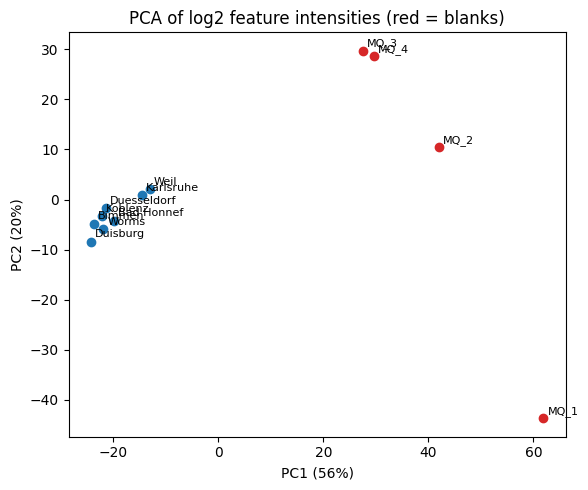

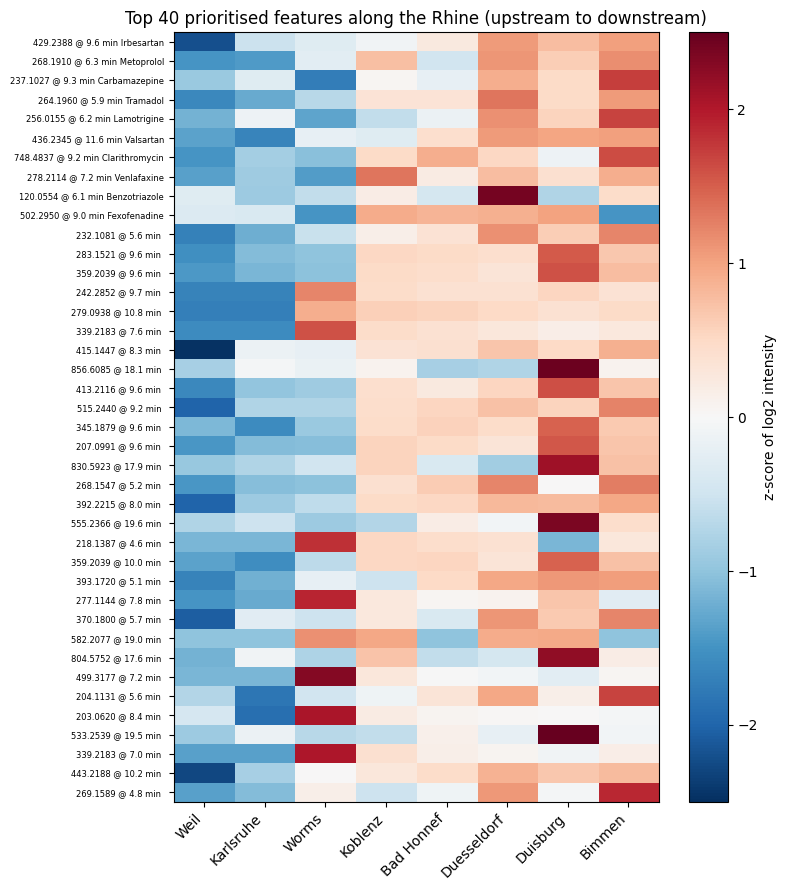

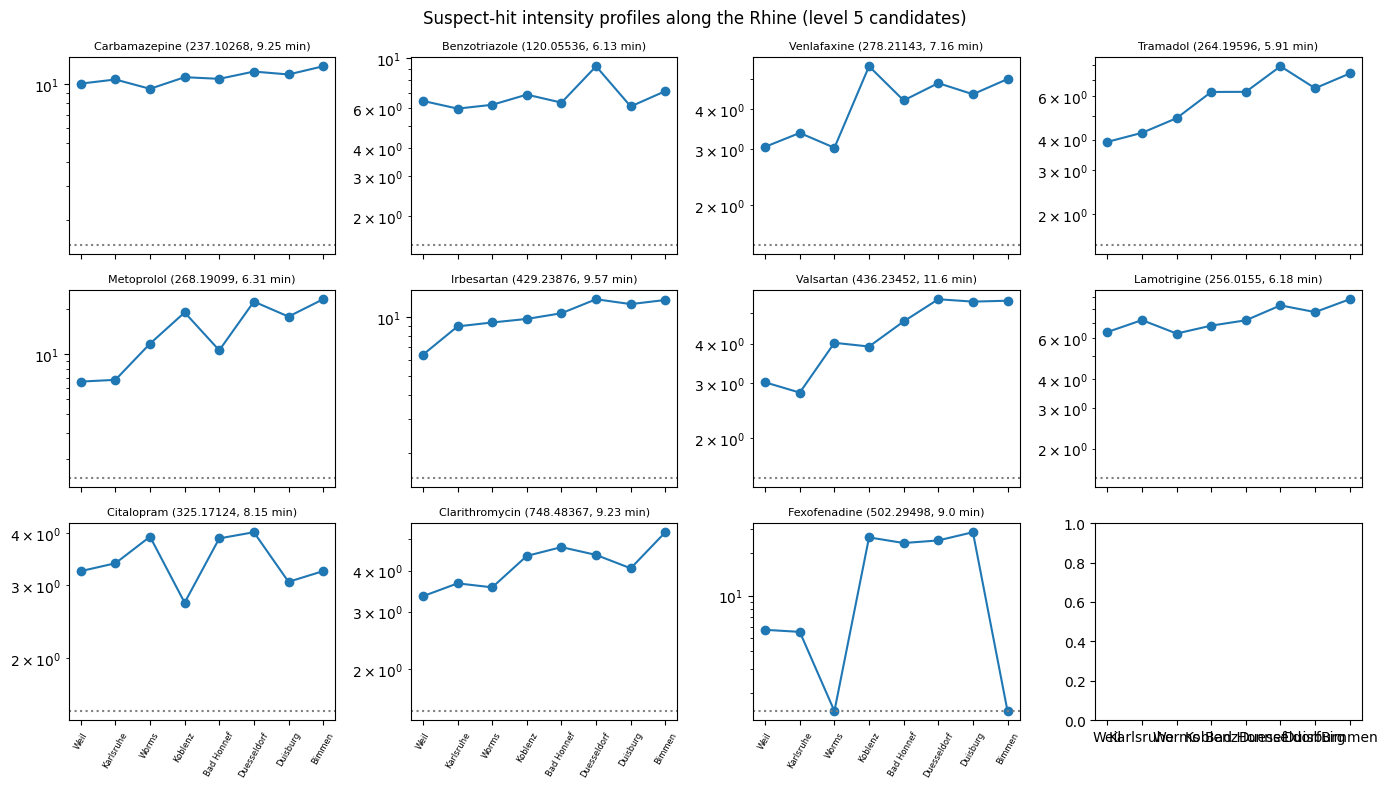

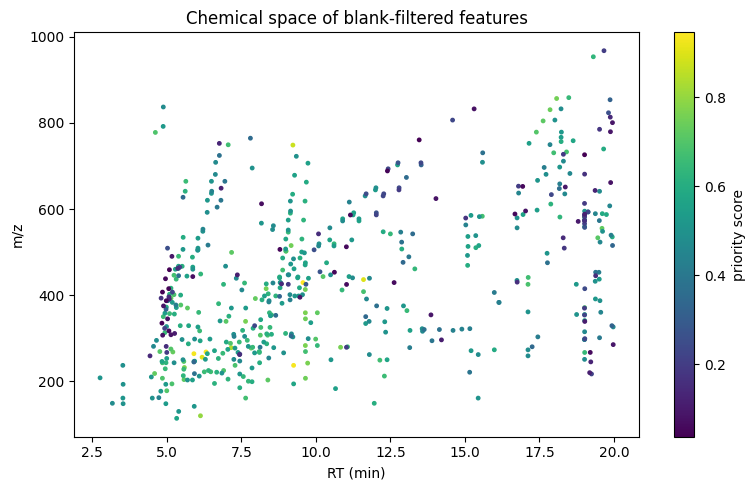

In [18]:
# Figures
from sklearn.decomposition import PCA
cols = SAMPLES + BLANKS
Xp = np.log2(np.maximum(M.loc[(M[cols] > 0).sum(axis=1) >= 2, cols].values.T, LOD))
pc = PCA(n_components=2).fit(Xp); Z = pc.transform(Xp)
fig, ax = plt.subplots(figsize=(6, 5))
for i, c in enumerate(cols):
    ax.scatter(Z[i, 0], Z[i, 1], c="tab:red" if c in BLANKS else "tab:blue"); ax.annotate(c, Z[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel(f"PC1 ({pc.explained_variance_ratio_[0]*100:.0f}%)"); ax.set_ylabel(f"PC2 ({pc.explained_variance_ratio_[1]*100:.0f}%)")
ax.set_title("PCA of log2 feature intensities (red = blanks)"); plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_pca.png", dpi=160); plt.show()

top = F.head(40)
Lt = np.log2(np.maximum(Sc.loc[top.index].values, LOD))
Zt = (Lt - Lt.mean(1, keepdims=True)) / np.where(Lt.std(1, keepdims=True) == 0, 1, Lt.std(1, keepdims=True))
fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(Zt, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
ax.set_xticks(range(len(SAMPLES))); ax.set_xticklabels(SAMPLES, rotation=45, ha="right")
ax.set_yticks(range(len(top))); ax.set_yticklabels([f"{m:.4f} @ {r:.1f} min {s.split('|')[0]}" for m, r, s in zip(top.mz, top.rt_min, top.suspect)], fontsize=6)
plt.colorbar(im, label="z-score of log2 intensity"); ax.set_title("Top 40 prioritised features along the Rhine (upstream to downstream)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_top_features_heatmap.png", dpi=160); plt.show()

if len(hits):
    hu = hits.drop_duplicates("compound").head(12)
    fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True)
    for ax, (_, h) in zip(axes.ravel(), hu.iterrows()):
        vals = np.maximum(Sc.loc[h.cid, SAMPLES].values, LOD)
        ax.plot(range(len(SAMPLES)), vals, "o-"); ax.set_yscale("log"); ax.axhline(LOD, ls=":", c="gray")
        ax.set_title(f"{h.compound} ({h.mz_obs}, {h.rt_min} min)", fontsize=8)
        ax.set_xticks(range(len(SAMPLES))); ax.set_xticklabels(SAMPLES, rotation=60, fontsize=6)
    plt.suptitle("Suspect-hit intensity profiles along the Rhine (level 5 candidates)"); plt.tight_layout()
    plt.savefig(FIG_DIR / "fig4_suspect_profiles.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(F.rt_min, F.mz, c=F.score, s=6, cmap="viridis"); plt.colorbar(sc, label="priority score")
ax.set_xlabel("RT (min)"); ax.set_ylabel("m/z"); ax.set_title("Chemical space of blank-filtered features")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_mz_rt_space.png", dpi=160); plt.show()

In [19]:
def lookup(mz_t, ppm=10):
    sel = M.index[np.abs(info.mz - mz_t) / mz_t * 1e6 <= ppm]
    out = M.loc[sel].copy()
    out.insert(0, "rt_min", (info.loc[sel, "rt"] / 60).round(2))
    out.insert(0, "mz", info.loc[sel, "mz"].round(4))
    return out.round(2)
 
for name in ["Clarithromycin", "Sitagliptin", "Diclofenac", "Caffeine", "Benzotriazole", "Gabapentin", "Sulfamethoxazole"]:
    print("\n", name, round(mono(SUSPECTS[name]) + PROTON, 4))
    t = lookup(mono(SUSPECTS[name]) + PROTON)
    print(t.to_string() if len(t) else "   no feature group near this mass")


 Clarithromycin 748.4842
sample      mz  rt_min  Weil  Karlsruhe  Worms  Koblenz  Bad Honnef  Duesseldorf  Duisburg  Bimmen  MQ_1  MQ_2  MQ_3  MQ_4
cid                                                                                                                       
5193    748.48    9.23  2.68       2.94   3.34     4.49        5.15         4.83      4.67    5.57   0.0   0.0   0.0   0.0

 Sitagliptin 408.1254
sample      mz  rt_min  Weil  Karlsruhe  Worms  Koblenz  Bad Honnef  Duesseldorf  Duisburg  Bimmen  MQ_1  MQ_2  MQ_3  MQ_4
cid                                                                                                                       
623     408.13   16.07   0.0        0.0    0.0      0.0         0.0          0.0       0.0     0.0   0.0   0.0   0.0   0.0

 Diclofenac 296.024
   no feature group near this mass

 Caffeine 195.0877
   no feature group near this mass

 Benzotriazole 120.0556
sample      mz  rt_min  Weil  Karlsruhe  Worms  Koblenz  Bad Honnef  Duesseld

In [20]:
cols_show = ["mz", "rt_min", "n_sites", "rho", "jump_up", "jump_site", "persist", "n_ms2", "score"]
print("Top 20 UNKNOWN features by score:")
print(F[F.suspect == ""].head(20)[cols_show].round(3).to_string())
ev = F[(F.jump_up >= 4) & (F.persist >= 0.8) & (F.n_ms2 > 0)].sort_values("jump_up", ascending=False)
print(f"\nEvent-like features (>= 16x jump, persist >= 80%, with MS2): {len(ev)}")
print(ev.head(25)[cols_show].round(3).to_string())
print("\nEvent-like features per jump site:"); print(ev.jump_site.value_counts().reindex(SAMPLES).fillna(0).astype(int).to_string())
ev.to_csv(OUT / "event_like_features.csv")

Top 20 UNKNOWN features by score:
           mz  rt_min  n_sites    rho  jump_up    jump_site  persist  n_ms2  score
cid                                                                               
1701  232.108   5.588        8  0.976    0.721  Duesseldorf    1.000      3  0.766
619   283.152   9.647        8  0.881    1.712     Duisburg    1.000     11  0.764
660   359.204   9.647        8  0.881    1.712     Duisburg    1.000     12  0.763
32    242.285   9.723        6  0.323    9.536        Worms    1.000     36  0.762
45    279.094  10.828        6  0.180    7.667        Worms    1.000      7  0.761
163   339.218   7.640        6  0.180    7.520        Worms    1.000      9  0.761
2916  415.145   8.331        8  0.952    0.740        Worms    1.000      8  0.754
228   856.608  18.076        7  0.455    5.356     Duisburg    1.000      5  0.751
2233  413.212   9.645        8  0.952    1.333     Duisburg    1.000      7  0.750
2809  515.244   9.169        8  0.976    0.633  Duess

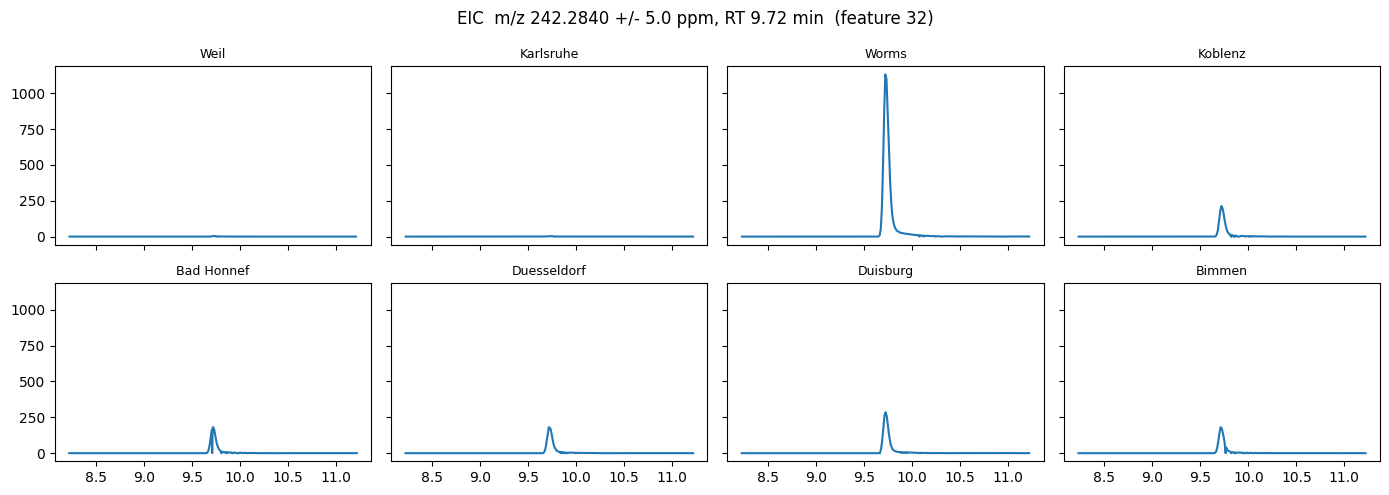

In [21]:
def plot_eic(cid, ppm=5.0, win=90.0):
    mz0, rt0 = F.loc[cid, "mz_raw"], F.loc[cid, "rt"]
    fig, axes = plt.subplots(2, 4, figsize=(14, 5), sharex=True, sharey=True)
    for ax, s in zip(axes.ravel(), SAMPLES):
        path = meta.loc[meta.name == s, "path"].iloc[0]
        scan_rt, mz_s, it_s, sid_s = load_ms1_flat(path)
        tol = mz0 * ppm * 1e-6
        lo, hi = np.searchsorted(mz_s, [mz0 - tol, mz0 + tol])
        a, b = np.searchsorted(scan_rt, [rt0 - win, rt0 + win])
        sid, v = sid_s[lo:hi], it_s[lo:hi]
        m = (sid >= a) & (sid < b)
        eic = np.bincount(sid[m] - a, weights=v[m], minlength=b - a)
        ax.plot(scan_rt[a:b] / 60, eic); ax.set_title(s, fontsize=9)
    fig.suptitle(f"EIC  m/z {mz0:.4f} +/- {ppm} ppm, RT {rt0/60:.2f} min  (feature {cid})")
    plt.tight_layout(); plt.savefig(FIG_DIR / f"eic_feature_{cid}.png", dpi=160); plt.show()
 
plot_eic(32)      # the strongest 'appears at Worms' feature; also try 45 and 163, and the carbamazepine candidate 2520

In [22]:
# Export
with open(OUT / "tier1_ms2.mgf", "w") as fh:
    for fid, r in F[(F.tier == "1") & (F.ms2_idx >= 0)].iterrows():
        rec = ms2_rows[int(r.ms2_idx)]; o = np.argsort(rec["mz"])
        pep = rec['pmz'] / (1 + (a + b * rec['pmz']) * 1e-6)
        fh.write(f"BEGIN IONS\nFEATURE_ID={fid}\nPEPMASS={pep:.5f}\nRTINSECONDS={rec['rt']:.1f}\nCHARGE=1+\nMSLEVEL=2\n")
        for m, i in zip(rec["mz"][o], rec["it"][o]): fh.write(f"{m:.5f} {i:.3f}\n")
        fh.write("END IONS\n\n")
params = dict(record=RECORD_ID, noise_quantile=NOISE_QUANTILE, noise_int=NOISE_INT, mass_error_ppm=MASS_ERR_PPM,
              group_ppm=PPM_TOL, group_rt_s=RT_TOL, blank_fold=BLANK_FOLD, min_sites=MIN_SITES, suspect_ppm=SUSPECT_PPM,
              weights=W, offset_ppm=OFFSET_PPM, apex_min=float(APEX_MIN), lod=float(LOD), suspect_ppm_used=SUSPECT_PPM, n_features_kept=int(len(F)), pyopenms=getattr(globals().get("oms", None), "__version__", "n/a"))
json.dump(params, open(OUT / "run_params.json", "w"), indent=2)
import shutil; shutil.make_archive(str(WORK / "rhine_pnta_results"), "zip", str(OUT))
print("Saved to", OUT, "(download the zip, and use Save Version > Save & Run All so outputs persist)")

Saved to /kaggle/working/wastewater_watch_results (download the zip, and use Save Version > Save & Run All so outputs persist)


In [23]:
# STRICT replacement for the "Homologous series" cell (the cell that starts with "# Homologous series ...").
# Paste this over that cell and run it (it only needs F, Sc, LOD, SAMPLES, OUT from the notebook).
# Why: the first version linked any two features 44.026 apart within 90 s, which happens by chance for ~0.5 partners per
# feature, so unrelated features chained into giant false "series". This version requires consecutive repeat units,
# a small RT step between neighbours, and a similar pattern along the river.
 
# %% Strict homologous series
UNITS = {"C2H4O (ethoxylate)": 44.026215, "C3H6O (propoxylate)": 58.041865}
MIN_RUN = 4          # at least 4 consecutive repeat units
RT_STEP = 20.0       # seconds: neighbouring oligomers elute close together
MIN_CORR = 0.5       # similar profile along the river
MZ_TOL = 0.002       # Da (differences cancel most of the mass error)
 
ids = F.index.values; mzr = F.mz_raw.values; rts = F.rt.values
prof = np.log2(np.maximum(Sc.loc[ids].values, LOD))
sid_arr = np.full(len(ids), -1); unit_arr = np.array([""] * len(ids), dtype=object); len_arr = np.zeros(len(ids), dtype=int)
next_id = 0
for uname, u in UNITS.items():
    parent = list(range(len(ids)))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for ia in range(len(ids)):
        d = mzr - mzr[ia] - u
        for ib in np.where((np.abs(d) <= MZ_TOL) & (np.abs(rts - rts[ia]) <= RT_STEP))[0]:
            c = np.corrcoef(prof[ia], prof[ib])[0, 1]
            if np.isfinite(c) and c >= MIN_CORR:
                ra, rb = find(ia), find(ib)
                if ra != rb: parent[ra] = rb
    comp = np.array([find(i) for i in range(len(ids))])
    for cmp in np.unique(comp):
        members = np.where(comp == cmp)[0]
        if len(members) < MIN_RUN: continue
        k = np.round((mzr[members] - mzr[members].min()) / u).astype(int)
        ks = np.unique(k); runs = []; start = prev = ks[0]
        for v in ks[1:]:
            if v != prev + 1: runs.append((start, prev)); start = v
            prev = v
        runs.append((start, prev))
        best = max(runs, key=lambda r: r[1] - r[0])
        run_len = best[1] - best[0] + 1
        if run_len >= MIN_RUN:
            sel = members[(k >= best[0]) & (k <= best[1])]
            sid_arr[sel] = next_id; unit_arr[sel] = uname; len_arr[sel] = run_len; next_id += 1
 
F["series_id"] = pd.Series(sid_arr, index=ids).reindex(F.index).values
F["series_unit"] = pd.Series(unit_arr, index=ids).reindex(F.index).values
F["series_len"] = pd.Series(len_arr, index=ids).reindex(F.index).values
ser = F[F.series_id >= 0].sort_values(["series_id", "mz_raw"])
print(f"{ser.series_id.nunique()} strict series (>= {MIN_RUN} consecutive units), {len(ser)} features")
for sid, g in ser.groupby("series_id"):
    print(f"\nSeries {sid}: {g.series_unit.iloc[0]}, {len(g)} members, sites detected {int(g.n_sites.min())}-{int(g.n_sites.max())}")
    print(g[["mz_raw", "rt_min", "n_sites", "jump_site", "jump_up"]].round(3).to_string())
 
last = len(SAMPLES) - 1
ev2 = F[(F.jump_up >= 4) & (F.persist >= 0.8) & (F.n_ms2 > 0) & (F.jump_site.map(SAMPLES.index) < last)].sort_values("jump_up", ascending=False)
ev2 = ev2.assign(in_series=ev2.series_id >= 0)
print(f"\nStricter event-like list: {len(ev2)} features, {int(ev2.in_series.sum())} belong to a strict series")
print(ev2.jump_site.value_counts().reindex(SAMPLES).fillna(0).astype(int).to_string())
ev2.to_csv(OUT / "event_like_features_strict.csv")

8 strict series (>= 4 consecutive units), 48 features

Series 0: C2H4O (ethoxylate), 5 members, sites detected 8-8
       mz_raw  rt_min  n_sites    jump_site  jump_up
cid                                                 
4204  358.242   4.935        8  Duesseldorf    0.394
3565  402.268   5.090        8  Duesseldorf    0.449
3137  446.295   5.239        8  Duesseldorf    0.632
4095  490.321   5.392        8  Duesseldorf    0.674
6121  534.347   5.548        8   Bad Honnef    0.477

Series 1: C2H4O (ethoxylate), 7 members, sites detected 2-2
       mz_raw  rt_min  n_sites jump_site  jump_up
cid                                              
1871  442.299   9.398        2    Bimmen    3.611
1228  486.325   9.467        2    Bimmen    4.364
991   530.352   9.530        2    Bimmen    4.737
954   574.378   9.587        2    Bimmen    4.791
1076  618.405   9.636        2    Bimmen    4.517
1380  662.431   9.680        2    Bimmen    4.132
2186  706.457   9.733        2    Bimmen    3.445

Se

In [24]:
# Are the Worms 'event' features a uniform plume, or independent signals?
w = ev2[ev2.jump_site == "Worms"].index
down = [s for s in SAMPLES[3:]]
ratio = Sc.loc[w, "Worms"] / Sc.loc[w, down].replace(0, np.nan).median(axis=1)
out = F.loc[w, ["mz_raw", "rt_min", "n_sites", "n_ms2"]].assign(worms_over_downstream=ratio.round(1)).sort_values("worms_over_downstream")
print(out.to_string())
print("\nIf the ratios are all similar, one plume or one sample effect is the likely explanation; widely different ratios suggest independent sources.")

          mz_raw     rt_min  n_sites  n_ms2  worms_over_downstream
cid                                                               
45    279.092445  10.827825        6      7                    2.3
1066  194.116752   5.170625        6      3                    4.3
1581  317.120322   6.100375        5      5                    5.2
1896  243.082705   4.850767        6      5                    5.3
1794  229.153707   4.946383        5     11                    5.5
983   277.113089   7.828725        7      7                    6.3
690   218.137499   4.588833        5     17                    6.5
967   298.073112   9.992275        6     15                    6.7
912   339.216884   6.985583        6      1                    6.7
32    242.283952   9.723192        6     36                    6.8
1003  288.215826   7.133900        5      7                    6.9
1502  161.105983   7.643442        6      6                    7.2
657   203.060838   8.388917        7     11                   

In [25]:
# MS2 test for the ethoxylate-type series. Paste as a NEW cell at the end of the notebook, after the strict-series cell.
# Idea: PEG / ethoxylate ions fragment into a "ladder" of peaks spaced by one C2H4O unit (44.0262 Da).
# If the series members show such ladders far more often than ordinary features do, the series is chemically credible.
# It only uses variables already in the notebook: F, ms2_rows, ms2_near, np, pd.
 
# %% MS2 ethoxylate-ladder check
EO = 44.026215
TOL = 0.005      # Da
 
def eo_pairs(rec):
    mz = np.sort(rec["mz"].astype(float))
    if len(mz) < 3: return 0
    d = mz[None, :] - mz[:, None]                 # all pairwise differences between fragment peaks
    return int((np.abs(d - EO) <= TOL).sum())     # number of peak pairs exactly one EO unit apart
 
def ladder_stats(cid):
    r = F.loc[cid]; idxs = ms2_near(r.mz_raw, r.rt)
    pairs = [eo_pairs(ms2_rows[j]) for j in idxs]
    return len(idxs), int(sum(p >= 2 for p in pairs)), (max(pairs) if pairs else 0)
 
rows = []
for sid, g in F[F.series_id >= 0].groupby("series_id"):
    for cid, r in g.sort_values("mz_raw").iterrows():
        n_ms2, n_lad, mx = ladder_stats(cid)
        rows.append(dict(series=sid, cid=cid, mz=round(r.mz_raw, 3), rt_min=round(r.rt_min, 2), n_ms2=n_ms2, ms2_with_ladder=n_lad, max_pairs=mx))
res = pd.DataFrame(rows)
print(res.to_string())
tot = res.groupby("series")[["n_ms2", "ms2_with_ladder"]].sum()
tot["fraction"] = (tot.ms2_with_ladder / tot.n_ms2.replace(0, np.nan)).round(2)
print("\nPer series:"); print(tot.to_string())
 
# control: ordinary features that are not in any series
ctrl_ids = F[(F.series_id < 0) & (F.n_ms2 > 0)].sample(min(150, int(((F.series_id < 0) & (F.n_ms2 > 0)).sum())), random_state=0).index
c = np.array([ladder_stats(i)[:2] for i in ctrl_ids])
print(f"\nControl (non-series features): {c[:, 1].sum()} of {c[:, 0].sum()} MS2 spectra show a ladder = {c[:, 1].sum() / max(c[:, 0].sum(), 1):.3f}")
print("A credible ethoxylate series should show a much higher fraction than the control.")
res.to_csv(OUT / "series_ms2_ladder_check.csv", index=False)

    series   cid       mz  rt_min  n_ms2  ms2_with_ladder  max_pairs
0        0  4204  358.242    4.94     20               20          7
1        0  3565  402.268    5.09     18               18          7
2        0  3137  446.295    5.24     29               29          8
3        0  4095  490.321    5.39     16               16          7
4        0  6121  534.347    5.55      6                5          5
5        1  1871  442.299    9.40      1                1          3
6        1  1228  486.325    9.47      3                3         15
7        1   991  530.352    9.53      2                2         10
8        1   954  574.378    9.59      4                4         13
9        1  1076  618.405    9.64      2                2         11
10       1  1380  662.431    9.68      3                3         17
11       1  2186  706.457    9.73      1                1         16
12       2  3382  356.190    5.25      2                0          1
13       2  2565  400.216    5.46 

## Interpretation notes and limitations (keep these in the write-up)
- The spatial gradient is a **proxy** for time; it supports method development, not a true early-warning test.
- Suspect hits are level 5 (exact mass) unless the MS2 fragment check supports them (then a tentative level 3). Verify fragment values in MassBank first; reference standards or library matches are needed for level 2 or 1.
- Hotspot / tributary explanations (for example Worms, Mosel, Ruhr) are hypotheses, not findings.
- Normalisation assumes most features do not change between sites; if run order equals river order, drift and real gradients cannot be fully separated without QC injections.
- Report the sensitivity of results to NOISE_QUANTILE, the blank choice and the score weights.
- Next: MetFrag + PubChemLite on tier1_ms2.mgf, matchms against MassBank, the paired negative-mode file.